# Lab01
## Описание датасета и случайных величин
В качестве источника данных выбран открытый датасет симулированных токов ионных каналов (Zenodo record 8288407). Датасет основан на двухсостояниевой модели гейтинга (closed/open) и содержит временные ряды с метками состояний (0/1) и значениями тока.

Для анализа выбраны три случайные величины:
1. **СВ 1: Время жизни в открытом состоянии (Open Dwell Time)** — длины непрерывных отрезков, где канал открыт (state = 1).
2. **СВ 2: Время жизни в закрытом состоянии (Closed Dwell Time)** — длины непрерывных отрезков, где канал закрыт (state = 0).
3. **СВ 3: Амплитуда тока в открытом состоянии (Current Amplitude)** — значения тока, соответствующие открытому состоянию канала.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import scipy.stats as stats
from scipy.stats import shapiro
import os

In [2]:
# Скачиваем архив (20 минут)
!wget -O channels.zip "https://zenodo.org/records/8288407/files/Datasets%20that%20simulated%20ion%20channel%20currents.zip?download=1"

# одна папка нужна
!unzip -q -o channels.zip "Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/*" -d channel_data

--2026-10-20 14:54:59--  https://zenodo.org/records/8288407/files/Datasets%20that%20simulated%20ion%20channel%20currents.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 137.138.121.78, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3658937673 (3.4G) [application/octet-stream]
Saving to: ‘channels.zip’

channels.zip        100%[===================>]   3.41G  4.67MB/s    in 15m 40s 

2026-10-20 15:10:40 (3.71 MB/s) - ‘channels.zip’ saved [3658937673/3658937673]



In [3]:
# 1. Находим первый CSV файл
file_paths = glob.glob('channel_data/**/*.csv', recursive=True)
file_path = file_paths[0]
print(f"Читаем файл: {file_path}\n")

# 2. Загружаем данные
df = pd.read_csv(file_path)
df.columns = [c.strip().lower() for c in df.columns]

# 3. Извлекаем состояния (0 или 1)
state_col = 'ground truth' if 'ground truth' in df.columns else df.columns[1]
states = df[state_col].values

# 4. Функция для извлечения длин непрерывных отрезков
def get_dwell_times(states, target):
    changes = np.where(np.diff(states) != 0)[0] + 1
    segments = np.split(states, changes)
    return np.array([len(seg) for seg in segments if len(seg) > 0 and seg[0] == target])

# Извлекаем в секундах
freq = 25000
open_dwell = get_dwell_times(states, 1) / freq
closed_dwell = get_dwell_times(states, 0) / freq

# 5. Извлекаем амплитуду тока
current_col = 'current' if 'current' in df.columns else df.columns[2]
current_open = df[current_col].values[states == 1]

print(f"СВ 1 (Open Dwell): {len(open_dwell)} значений")
print(f"СВ 2 (Closed Dwell): {len(closed_dwell)} значений")
print(f"СВ 3 (Current Amplitude): {len(current_open)} значений")

Читаем файл: channel_data/Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/k1=100-k2=100-5.csv

СВ 1 (Open Dwell): 1008 значений
СВ 2 (Closed Dwell): 1009 значений
СВ 3 (Current Amplitude): 249930 значений


## Random Variable 01: Время жизни в открытом состоянии
### Природа события
Канал (белок) под действием света или спонтанно меняет конформацию и открывается. Время, которое он проводит в открытом состоянии, зависит от кинетики связывания ионов и конформационных переходов. Согласно двухсостояниевой модели гейтинга, эти времена описываются экспоненциальным распределением. Процесс является стохастическим, так как переходы между состояниями происходят случайно.

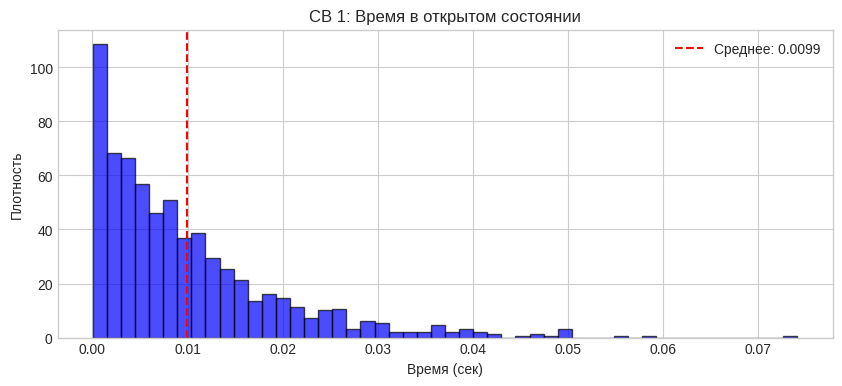

Статистики: mean=0.0099, std=0.0098, median=0.0071


In [14]:
plt.figure(figsize=(10, 4))
plt.hist(open_dwell, bins=50, density=True, alpha=0.7, color='blue', edgecolor='black')
plt.title('СВ 1: Время в открытом состоянии')
plt.xlabel('Время (сек)')
plt.ylabel('Плотность')
plt.axvline(np.mean(open_dwell), color='red', linestyle='dashed', label=f'Среднее: {np.mean(open_dwell):.4f}')
plt.legend()
plt.show()

print(f"Статистики: mean={np.mean(open_dwell):.4f}, std={np.std(open_dwell):.4f}, median={np.median(open_dwell):.4f}")

**Вывод:** Гистограмма имеет падающий вид (экспоненциальный спад), что подтверждает случайную (стохастическую) природу величины. Значения нельзя вычислить детерминированной формулой.

## Random Variable 02: Время жизни в закрытом состоянии
### Природа события
Время, в течение которого канал находится в закрытом состоянии, также является случайной величиной, зависящей от вероятности спонтанного открытия или закрытия. В двухсостояниевой модели оно подчиняется экспоненциальному закону.

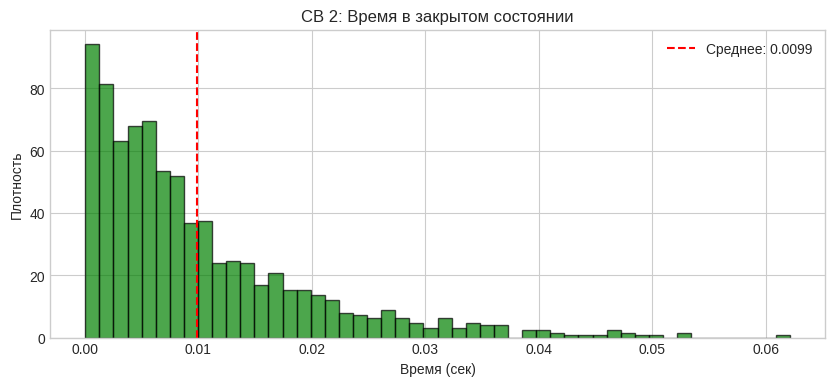

Статистики: mean=0.0099, std=0.0096, median=0.0068


In [15]:
plt.figure(figsize=(10, 4))
plt.hist(closed_dwell, bins=50, density=True, alpha=0.7, color='green', edgecolor='black')
plt.title('СВ 2: Время в закрытом состоянии')
plt.xlabel('Время (сек)')
plt.ylabel('Плотность')
plt.axvline(np.mean(closed_dwell), color='red', linestyle='dashed', label=f'Среднее: {np.mean(closed_dwell):.4f}')
plt.legend()
plt.show()

print(f"Статистики: mean={np.mean(closed_dwell):.4f}, std={np.std(closed_dwell):.4f}, median={np.median(closed_dwell):.4f}")

**Вывод:** Распределение также имеет падающий вид.


##Проверим независимость времени открытого и закрытого состояний (СВ 1 и СВ 2).

In [16]:
min_len = min(len(open_dwell), len(closed_dwell))
corr, p_value = stats.pearsonr(open_dwell[:min_len], closed_dwell[:min_len])
print(f"Корреляция Пирсона: {corr:.4f} (p-value: {p_value:.4e})")
if p_value > 0.05:
    print("Вывод: Корреляция статистически незначима. Величины независимы.")
else:
    print("Вывод: Есть статистически значимая корреляция.")

Корреляция Пирсона: -0.0502 (p-value: 1.1103e-01)
Вывод: Корреляция статистически незначима. Величины независимы.


## Random Variable 03: Амплитуда тока в открытом состоянии
### Природа события
Амплитуда тока, протекающего через открытый канал, не является строго постоянной из-за теплового шума и флуктуаций ионных потоков. Это случайная величина, которая, согласно центральной предельной теореме, должна подчиняться нормальному распределению.

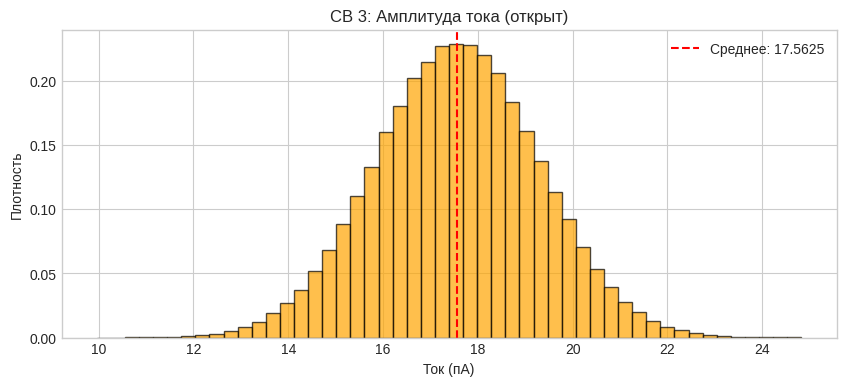

Тест Шапиро-Уилка: p-value = 5.5001e-01
Вывод: Распределение статистически неотличимо от нормального.


In [17]:
plt.figure(figsize=(10, 4))
plt.hist(current_open, bins=50, density=True, alpha=0.7, color='orange', edgecolor='black')
plt.title('СВ 3: Амплитуда тока (открыт)')
plt.xlabel('Ток (пА)')
plt.ylabel('Плотность')
plt.axvline(np.mean(current_open), color='red', linestyle='dashed', label=f'Среднее: {np.mean(current_open):.4f}')
plt.legend()
plt.show()

# Тест Шапиро-Уилка
sample_current = np.random.choice(current_open, size=5000, replace=False)
stat, p = shapiro(sample_current)
print(f"Тест Шапиро-Уилка: p-value = {p:.4e}")
if p > 0.05:
    print("Вывод: Распределение статистически неотличимо от нормального.")

**Вывод:** Гистограмма имеет вид «колокола». Тест Шапиро-Уилка подтвердил нормальное распределение. Величина является случайной (суперпозиция множества мелких шумов).

### Состоятельность оценок
Проверим сходимость выборочного среднего при росте выборки для всех трех величин.

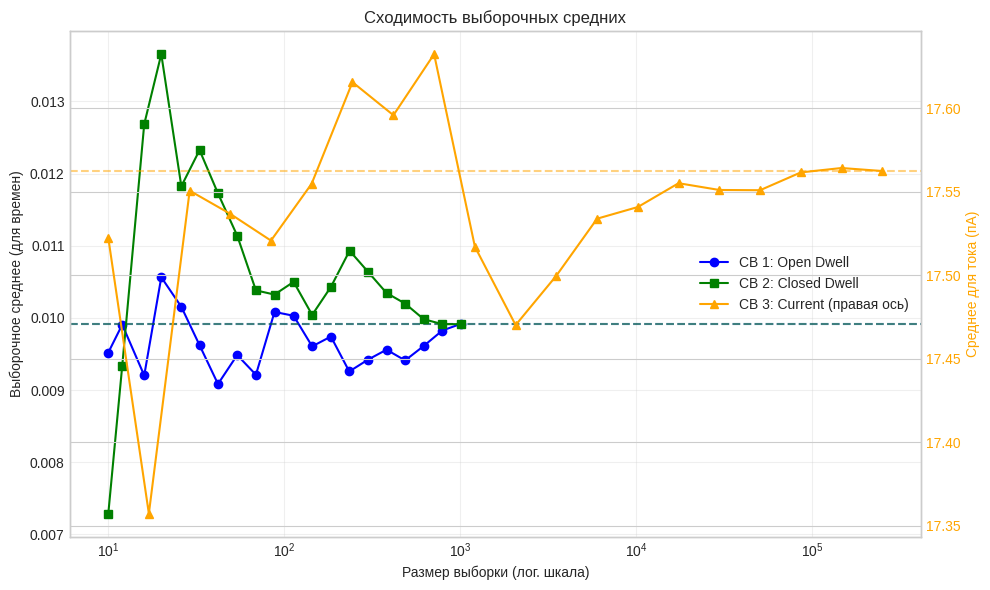

In [18]:
sizes_open = np.logspace(1, np.log10(len(open_dwell)), 20).astype(int)
sizes_closed = np.logspace(1, np.log10(len(closed_dwell)), 20).astype(int)
sizes_current = np.logspace(1, np.log10(len(current_open)), 20).astype(int)

means_open = [np.mean(open_dwell[:s]) for s in sizes_open]
means_closed = [np.mean(closed_dwell[:s]) for s in sizes_closed]
means_current = [np.mean(current_open[:s]) for s in sizes_current]

plt.figure(figsize=(10, 6))
plt.plot(sizes_open, means_open, marker='o', color='blue', label='СВ 1: Open Dwell')
plt.axhline(np.mean(open_dwell), color='blue', linestyle='dashed', alpha=0.5)
plt.plot(sizes_closed, means_closed, marker='s', color='green', label='СВ 2: Closed Dwell')
plt.axhline(np.mean(closed_dwell), color='green', linestyle='dashed', alpha=0.5)

ax1 = plt.gca()
ax2 = ax1.twinx()
ax2.plot(sizes_current, means_current, marker='^', color='orange', label='СВ 3: Current (правая ось)')
ax2.axhline(np.mean(current_open), color='orange', linestyle='dashed', alpha=0.5)
ax2.set_ylabel('Среднее для тока (пА)', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

ax1.set_xscale('log')
ax1.set_xlabel('Размер выборки (лог. шкала)')
ax1.set_ylabel('Выборочное среднее (для времен)')
ax1.set_title('Сходимость выборочных средних')
ax1.grid(True, alpha=0.3)

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')
plt.tight_layout()
plt.show()



### Выводы
1. Время жизни канала в открытом и закрытом состояниях является случайной величиной с экспоненциальным распределением, что подтверждает стохастическую природу процесса.
2. Время открытого и закрытого состояний независимы (корреляция незначима, p > 0.05).
3. Оценка среднего состоятельна для всех трех величин (сходится с ростом выборки).
4. Амплитуда тока подчиняется нормальному закону распределения (подтверждено тестом Шапиро-Уилка).

### cat_mark_table
| cat_id | notebook_link | coeff | comment |
|--------|-----------------|-------|---------|
| 1      | (вставь ссылку на GitHub) | 1.0   | Спринт 1 выполнен |